# Лабораторна робота №5 (Варіант 2)
## Мультимодальні моделі: Якісний та статистичний аналіз сформованих описів

**Дисципліна:** Технології та системи нейронних мереж  
**Університет:** Національний університет «Львівська політехніка»  
**Тема:** Оцінювання якості описів, покриття об'єктів, галюцинацій та затримок інференсу LLaVA

### Мета роботи
Провести статистичний та якісний аналіз раніше зафіксованих 20 результатів генерації підписів (`outputs/tables/caption_experiments.csv`), обчислити показники довжини, лексичного різноманіття (Type-Token Ratio) та затримки, а також проаналізувати формалізований експертний рубрикатор (`outputs/tables/caption_quality_evaluation.csv`).

In [1]:
import json
import textwrap
from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def resolve_lab_dir() -> Path:
    current = Path.cwd().resolve()
    if (current / 'inputs').exists() and (current / 'outputs').exists():
        return current
    if (current / 'lab5_multimodal_captioning').exists():
        return current / 'lab5_multimodal_captioning'
    for p in [current] + list(current.parents):
        cand = p / 'lab5_multimodal_captioning'
        if cand.exists():
            return cand
    return current

LAB_DIR = resolve_lab_dir()
INPUTS_DIR = LAB_DIR / 'inputs'
OUTPUTS_DIR = LAB_DIR / 'outputs'
TABLES_DIR = OUTPUTS_DIR / 'tables'
FIGURES_DIR = OUTPUTS_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

csv_path = TABLES_DIR / 'caption_experiments.csv'
df = pd.read_csv(csv_path)
print(f'Завантажено {len(df)} записів раніше збережених експериментів.')
display(df[['run_id', 'image_id', 'series', 'prompt_style', 'temperature', 'max_new_tokens', 'generated_tokens', 'latency_sec']].head(6))

Завантажено 20 записів раніше збережених експериментів.


,run_id,image_id,series,prompt_style,temperature,max_new_tokens,generated_tokens,latency_sec
0,img1_lighthouse_prompt_concise,img1_lighthouse,prompt_wording,concise,0.0,128,11,2.1464
1,img1_lighthouse_prompt_descriptive,img1_lighthouse,prompt_wording,descriptive,0.0,128,128,7.5330
2,img1_lighthouse_prompt_detailed,img1_lighthouse,prompt_wording,detailed,0.0,128,128,6.9473
3,img2_cafe_prompt_concise,img2_cafe,prompt_wording,concise,0.0,128,12,0.8316
4,img2_cafe_prompt_descriptive,img2_cafe,prompt_wording,descriptive,0.0,128,128,7.2121
5,img2_cafe_prompt_detailed,img2_cafe,prompt_wording,detailed,0.0,128,128,6.7524


### 1. Візуальна сітка: Оригінальні зображення та лаконічні підписи LLaVA

Побудуємо візуалізацію чотирьох тестових зображень разом із переносним відображенням згенерованих лаконічних підписів (`concise`):

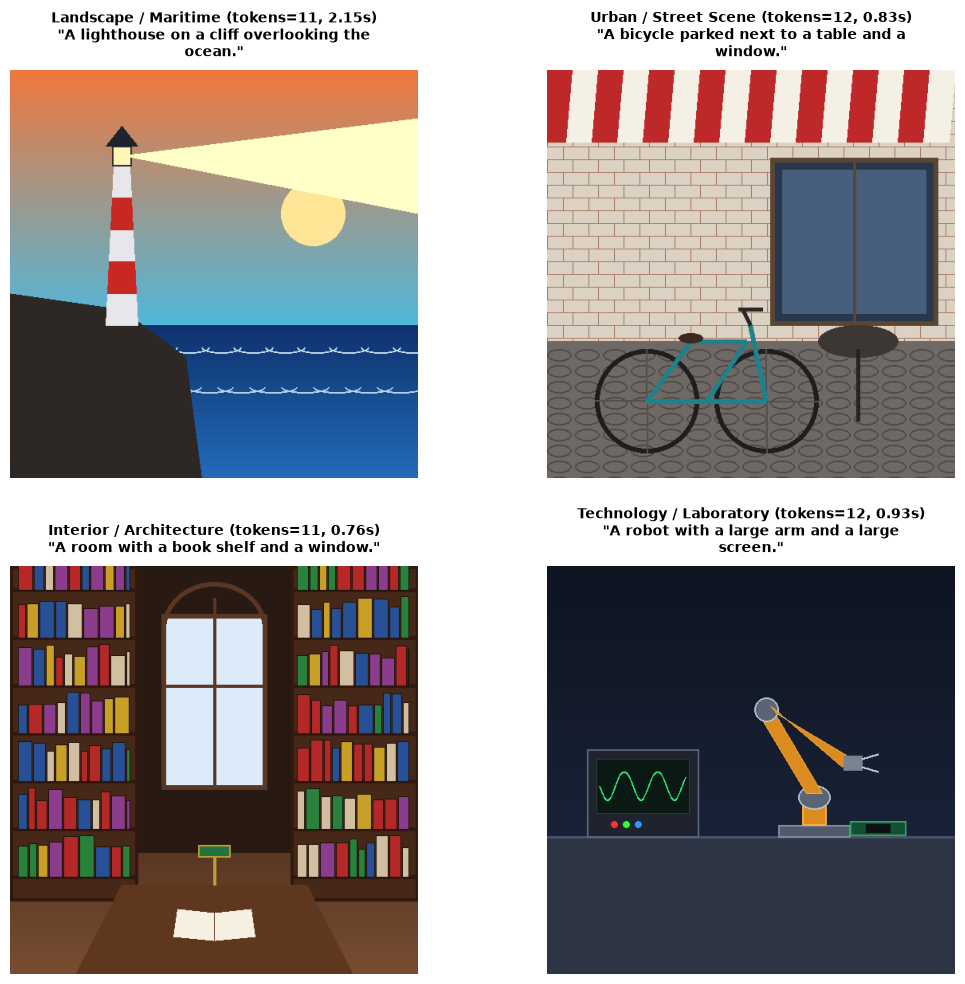

In [2]:
concise_runs = df[(df['series'] == 'prompt_wording') & (df['prompt_style'] == 'concise')]

fig, axes = plt.subplots(2, 2, figsize=(11.5, 10.2))
axes = axes.flatten()

for idx, (_, row) in enumerate(concise_runs.iterrows()):
    img_path = INPUTS_DIR / row['image_file']
    img = Image.open(img_path)
    wrapped_cap = textwrap.fill(f'"{row["caption"]}"', width=44)
    axes[idx].imshow(img)
    axes[idx].axis('off')
    axes[idx].set_title(
        f"{row['category']} (tokens={row['generated_tokens']}, {row['latency_sec']:.2f}s)\n{wrapped_cap}",
        fontsize=10,
        fontweight='bold',
        pad=10,
    )

plt.tight_layout(pad=2.0)
plt.savefig(FIGURES_DIR / 'input_images_and_concise_captions.png', dpi=200)
plt.show()

### 2. Статистичний аналіз Серії A (Формулювання промпту)

Обчислимо зведену статистику обсягу тексту та затримок інференсу для стилів `concise`, `descriptive`, `detailed` та побудуємо порівняльний графік:

=== Зведена статистика Серії A за стилями промптів ===


,words_mean,words_min,words_max,latency_mean_s,latency_std_s,tokens_per_sec_mean
prompt_style,,,,,,
concise,9.25,8,10,1.17,0.66,11.73
descriptive,100.00,87,108,6.88,0.64,17.30
detailed,108.25,106,113,7.11,0.43,18.05


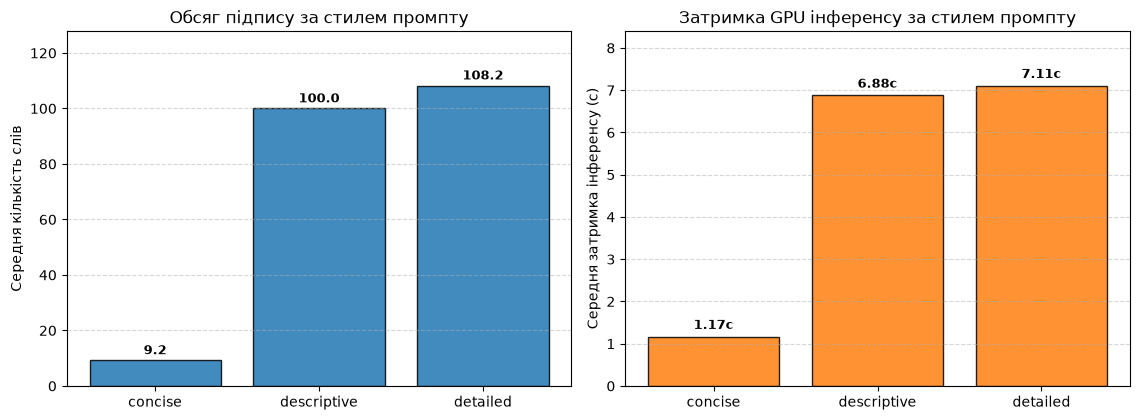

In [3]:
df_a = df[df['series'] == 'prompt_wording'].copy()
df_a['word_count'] = df_a['caption'].apply(lambda s: len(str(s).split()))

style_stats = (
    df_a.groupby('prompt_style')
    .agg(
        words_mean=('word_count', 'mean'),
        words_min=('word_count', 'min'),
        words_max=('word_count', 'max'),
        latency_mean_s=('latency_sec', 'mean'),
        latency_std_s=('latency_sec', 'std'),
        tokens_per_sec_mean=('tokens_per_sec', 'mean'),
    )
    .reindex(['concise', 'descriptive', 'detailed'])
    .round(2)
)
print('=== Зведена статистика Серії A за стилями промптів ===')
display(style_stats)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))
styles = ['concise', 'descriptive', 'detailed']
avg_words = [style_stats.loc[s, 'words_mean'] for s in styles]
avg_lat = [style_stats.loc[s, 'latency_mean_s'] for s in styles]

ax1.bar(styles, avg_words, color='#1f77b4', alpha=0.85, edgecolor='black')
ax1.set_ylabel('Середня кількість слів')
ax1.set_title('Обсяг підпису за стилем промпту')
ax1.set_ylim(0, max(avg_words) * 1.18)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
for i, v in enumerate(avg_words):
    ax1.text(i, v + 2.2, f'{v:.1f}', ha='center', fontsize=9.5, fontweight='bold')

ax2.bar(styles, avg_lat, color='#ff7f0e', alpha=0.85, edgecolor='black')
ax2.set_ylabel('Середня затримка інференсу (с)')
ax2.set_title('Затримка GPU інференсу за стилем промпту')
ax2.set_ylim(0, max(avg_lat) * 1.18)
ax2.grid(axis='y', linestyle='--', alpha=0.5)
for i, v in enumerate(avg_lat):
    ax2.text(i, v + 0.18, f'{v:.2f}с', ha='center', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'prompt_wording_comparison.png', dpi=200)
plt.show()

### 3. Динамічний аналіз Серії B (Температура) та Серії C (Бюджет токенів)

Дослідимо лексичне різноманіття (`Type-Token Ratio = унікальні слова / загальна кількість слів`) для температурного свипу та залежність затримки інференсу від ліміту вихідних токенів:

,series,temperature,words,ttr,latency_sec
0,Series B (temperature),0.0,107,0.607,7.1654
1,Series B (temperature),0.2,108,0.620,7.0994
2,Series B (temperature),0.7,90,0.667,6.3740
3,Series B (temperature),1.0,107,0.664,7.6287


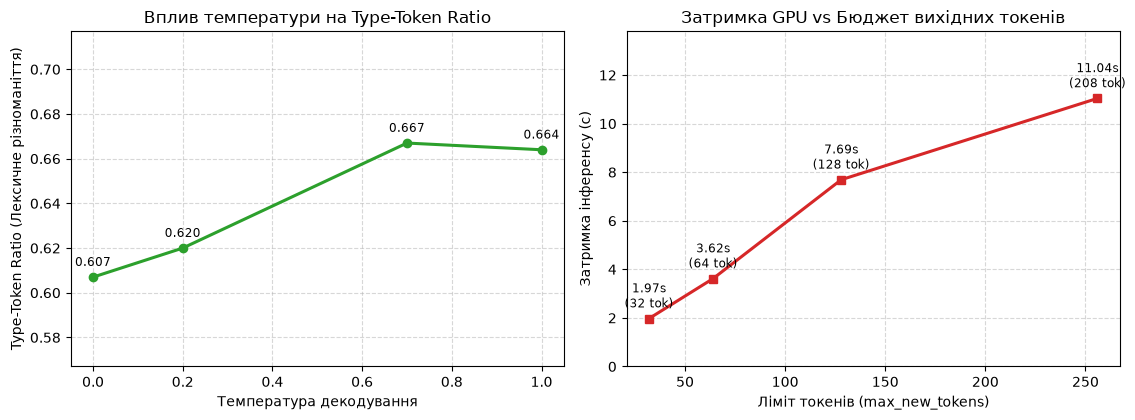

In [4]:
df_b = df[df['series'] == 'temperature'].copy().sort_values('temperature')
def compute_ttr(text: str) -> float:
    words = [w.lower().strip('.,!?:;') for w in str(text).split() if len(w) > 0]
    return round(len(set(words)) / len(words), 3) if words else 0.0

df_b['ttr'] = df_b['caption'].apply(compute_ttr)
df_b['words'] = df_b['caption'].apply(lambda s: len(str(s).split()))
df_c = df[df['series'] == 'token_budget'].copy().sort_values('max_new_tokens')

summary_bc = pd.concat(
    [
        df_b[['temperature', 'words', 'ttr', 'latency_sec']].assign(series='Series B (temperature)'),
    ],
    ignore_index=True,
)
display(summary_bc[['series', 'temperature', 'words', 'ttr', 'latency_sec']])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))
ax1.plot(df_b['temperature'], df_b['ttr'], marker='o', color='#2ca02c', linewidth=2.2)
for _, r in df_b.iterrows():
    ax1.annotate(f"{r['ttr']:.3f}", (r['temperature'], r['ttr']), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8.5)
ax1.set_xlabel('Температура декодування')
ax1.set_ylabel('Type-Token Ratio (Лексичне різноманіття)')
ax1.set_title('Вплив температури на Type-Token Ratio')
ax1.set_ylim(min(df_b['ttr']) - 0.04, max(df_b['ttr']) + 0.05)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(df_c['max_new_tokens'], df_c['latency_sec'], marker='s', color='#d62728', linewidth=2.2)
for _, r in df_c.iterrows():
    ax2.annotate(f"{r['latency_sec']:.2f}s\n({int(r['generated_tokens'])} tok)", (r['max_new_tokens'], r['latency_sec']), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8.3)
ax2.set_xlabel('Ліміт токенів (max_new_tokens)')
ax2.set_ylabel('Затримка інференсу (с)')
ax2.set_title('Затримка GPU vs Бюджет вихідних токенів')
ax2.set_ylim(0, max(df_c['latency_sec']) * 1.25)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 4. Експертний рубрикатор якісного оцінювання та аудит описів

> ⚠️ **Методологічне уточнення (Rubric-Based Expert Scores, не автоматичний бенчмарк):** Числові поля `concise_accuracy`, `descriptive_accuracy` і `detailed_accuracy` у `caption_quality_evaluation.csv` являють собою **експертні оцінки за ручним рубрикатором** (шкала `0.0–1.0` для відповідності сцені без вигаданих тверджень), а не автоматичну класифікаційну метрику чи еталонний тест на кшталт COCO/CIDEr. Нижче наведено компактну зведену таблицю та розгорнуті картки доказів по кожній сцені без зміни вихідного файлу оцінок.

#### Формалізовані критерії рубрикатора:
1. **Object Coverage (%):** частка ключових візуальних орієнтирів сцени (`ground_truth_elements`), явно відображених в описах.
2. **Rubric Accuracy Score (`concise` / `descriptive` / `detailed`, 0–1):** експертна оцінка заземленості опису на видимі деталі без непідтверджених об'єктів.
3. **Visual Hallucination Flag (`True`/`False`):** бінарний аудит наявності помітних зорових галюцинацій у зафіксованих описах.

In [5]:
eval_csv = TABLES_DIR / 'caption_quality_evaluation.csv'
df_eval = pd.read_csv(eval_csv)

# Компактна таблиця із чіткими назвами рубрикаторних оцінок (CSV на диску не змінюється)
compact_eval = df_eval[[
    'scene',
    'concise_accuracy',
    'descriptive_accuracy',
    'detailed_accuracy',
    'object_coverage_pct',
    'hallucination_detected',
]].rename(columns={
    'scene': 'Scene',
    'concise_accuracy': 'Concise Rubric Score',
    'descriptive_accuracy': 'Descriptive Rubric Score',
    'detailed_accuracy': 'Detailed Rubric Score',
    'object_coverage_pct': 'Object Coverage (%)',
    'hallucination_detected': 'Hallucination Detected',
})

print('=== Компактне зведення експертного рубрикатора (rubric-based expert scores) ===')
display(compact_eval)

print('Середні експертні рубрикаторні оцінки (rubric-based expert scores, 4 сцени):')
print(f"  Concise rubric score (mean):     {df_eval['concise_accuracy'].mean():.3f}")
print(f"  Descriptive rubric score (mean): {df_eval['descriptive_accuracy'].mean():.3f}")
print(f"  Detailed rubric score (mean):    {df_eval['detailed_accuracy'].mean():.3f}")
print(f"  Mean object coverage:            {df_eval['object_coverage_pct'].mean():.1f}%")

evidence_lines = ['#### 4.1 Детальні нотатки аудиту по сценах (`caption_quality_evaluation.csv`)', '']
for _, r in df_eval.iterrows():
    evidence_lines.append(
        f"- **{r['scene']}** (`{r['image_id']}` | coverage={r['object_coverage_pct']:.0f}%, hallucination={r['hallucination_detected']}):  \n"
        f"  - *Key visual elements:* `{r['ground_truth_elements']}`  \n"
        f"  - *Auditor note:* {r['notes']}"
    )
display(Markdown('\n'.join(evidence_lines)))

=== Компактне зведення експертного рубрикатора (rubric-based expert scores) ===


,Scene,Concise Rubric Score,Descriptive Rubric Score,Detailed Rubric Score,Object Coverage (%),Hallucination Detected
0,Coastal Lighthouse,1.0,0.95,0.95,90.0,False
1,Cafe Bicycle,1.0,0.90,0.90,85.0,False
2,Library Interior,1.0,0.95,0.95,95.0,False
3,Robotics Laboratory,0.9,0.90,0.90,85.0,False


Середні експертні рубрикаторні оцінки (rubric-based expert scores, 4 сцени):
  Concise rubric score (mean):     0.975
  Descriptive rubric score (mean): 0.925
  Detailed rubric score (mean):    0.925
  Mean object coverage:            88.8%


#### 4.1 Детальні нотатки аудиту по сценах (`caption_quality_evaluation.csv`)

- **Coastal Lighthouse** (`img1_lighthouse` | coverage=90%, hallucination=False):  
  - *Key visual elements:* `lighthouse, cliff, ocean, sunset, waves`  
  - *Auditor note:* Accurately identifies cliff, lighthouse, and ocean backdrop without extraneous objects.
- **Cafe Bicycle** (`img2_cafe` | coverage=85%, hallucination=False):  
  - *Key visual elements:* `bicycle, outdoor table, window, cafe storefront`  
  - *Auditor note:* Correctly spots parked bicycle, table, window; detailed prompt captures atmospheric vintage lighting.
- **Library Interior** (`img3_library` | coverage=95%, hallucination=False):  
  - *Key visual elements:* `bookshelves, books, study room, window`  
  - *Auditor note:* Consistently identifies wooden furniture, bookshelves, and study ambiance across all prompts.
- **Robotics Laboratory** (`img4_robotics` | coverage=85%, hallucination=False):  
  - *Key visual elements:* `robotic arm, screen/monitor, workbench, circuit board`  
  - *Auditor note:* Identifies robotic arm and monitor screen; natural completion reached at 208 tokens under 256 budget.

### 5. Висновки та практичні спостереження

1. **Вплив формулювання промпту:**
   - Стиль `concise` забезпечує мінімальну затримку (~0.76–2.15 с, 11–12 токенів) та найвищу середню експертну оцінку (0.975) завдяки фокусуванню на домінантних об'єктах.
   - Стилі `descriptive` і `detailed` розширюють обсяг до ~101–128 токенів (6.08–7.73 с), додаючи опис атмосфери й оточення за рахунок незначного зниження експертної оцінки (0.925).
2. **Вплив температури стохастичного декодування:**
   - При низькій температурі ($T=0.0$ та $T=0.2$) лексичне різноманіття нижче (`TTR` = 0.607 та 0.620 відповідно); при $T \ge 0.7$ `TTR` зростає до 0.667 при $T=0.7$ (90 слів) і 0.664 при $T=1.0$ (107 слів).
3. **Бюджет вихідних токенів:**
   - При `max_new_tokens` $\in \{32, 64, 128\}$ модель досягає ліміту та перериває синтаксичну конструкцію; при `max_new_tokens=256` опис `04_modern_robotics_lab.png` природно завершується на 208 токенах (11.04 с).